**Run copy for `wheel9`** — the 4 no-split clusters × direction of the movement's FIRST HALF + still (`nosplit_states.py 4 --sided --first-half`); otherwise identical to `lda_wheel_correlates.ipynb`.

# What does the LDA capture once the wheel is in it?

The paper's mouse-weighted shrinkage LDA (`lda_shrinkage_core.MouseEmbedding`, shrinkage 0.5 as the saved embedding `mouse_LDA_5_bins_raw_shrink0.5_wmouse_360`) refitted on the syllable features **plus the wheel movement states** (3.4, as one-hot per bin; features from `wheel_lda_test.py`), then the two analyses of `fig_ld1`:
1. **syllable correlations**: per trial bin, the correlation across sessions between a state's occupancy and LD1 (permutation band), now including the wheel states;
2. **trial-metric correlations**: `LDA_behavior`'s session summaries (accuracy, bias, RT, elongation, trials, training time) against LD1;

and the other LD1 correlations of the paper:

3. **engagement** (`fig_engagement`): the 2-state GLM-HMM session measures (fraction engaged, engaged log ratio, state switches, switches at equal accuracy, P(stay), switches at K = 4, held-out gain of more states) against LD1;
4. **neural** (`fig_neural`): `lda1_neural_metrics.run_tests` -- firing rate, Fano factor and r_SC against LD1 (GLM slope with region and trial-count covariates, session permutation).

Everything is shown for the new LD1 and, side by side, the production LD1, so the question is what the wheel changes. `VARIANT` picks the wheel state set (all states include `still`):
- `wheel7`: no split, no merge -- one GMM, 6 clusters (`representation_learning/wheel_movements/nosplit_states.py`);
- `wheel8`: still, small, side × mid / high (21-model grouped `small_side_vigor`);
- `wheel10`: side × vigor (21-model grouped `side_vigor`);
- `wheel13`: the 6 no-split clusters × whole-movement direction CW / CCW (`nosplit_states.py --sided`);
- `wheel17`: 21-model grouped `sided_both2`;
- `wheel21`: all 20 clusters of the 21-model, no merge.

In [1]:
import sys, pathlib, glob, re
import numpy as np, pandas as pd, matplotlib.pyplot as plt
import matplotlib.patheffects as pe
from scipy.stats import pearsonr
from statsmodels.stats.multitest import multipletests

REPO = pathlib.Path.cwd().resolve()
while not (REPO / 'Functions' / 'trial_modes.py').exists() and REPO != REPO.parent:
    REPO = REPO.parent
PI = REPO / 'paper-individuality'
for p in [PI, PI / 'learning_individuality', PI / '4_mice', PI / 'segmentation']:
    sys.path.insert(0, str(p))
import paper_style as ps
import lda_shrinkage_core as lsc
import wheel_lda_test as wlt
import wheel_movement_clusters as wmc
ps.use('paper', dpi=110); ps.use_paw_states('uniform')

VARIANT = 'wheel9'               # one of wheel7, wheel8, wheel10, wheel13, wheel17, wheel21 (see the top)
K_WHEEL = int(VARIANT[5:])
SHRINKAGE = 0.5                  # as the saved production embedding
LDA_FILE = PI / 'clustering' / 'data_files' / 'mouse_LDA_5_bins_raw_shrink0.5_wmouse_360_02-10-2026'
TRIAL_META = PI / 'data' / 'session_trial_meta_19-08-2026'
TRAINING_FILE = REPO / 'learning_prediction' / 'training_time_05-05-2026'
N_PERMS, SEED = 1000, 0
EPOCHS = ps.EPOCH_NAMES

import pickle
if K_WHEEL in (5, 7):            # no-split model, K_WHEEL - 1 clusters, no merge
    with open(wmc.states_dir('proficient') + f'model_k{K_WHEEL}_nosplit.pkl', 'rb') as _f:
        WM = pickle.load(_f)
    W_NAMES = wmc.state_names(WM)
    W_COLORS = ['#BDBDBD'] + wmc.colours(WM)[1:]
elif K_WHEEL in (9, 13):         # no-split clusters x direction: state = 1 + 2c + (CCW); 9 = first-half direction
    with open(wmc.states_dir('proficient') + f'model_k{K_WHEEL}_nosplit_sided.pkl', 'rb') as _f:
        WM = pickle.load(_f)
    _pk = WM['desc'].peak_rad_s.values
    W_NAMES = ['still'] + [f'U{c + 1} {d}' for c in range(WM['K']) for d in ('CW', 'CCW')]
    W_COLORS = ['#BDBDBD'] + ps.state_palette(np.log(np.repeat(_pk, 2)), gap=-wmc.CHROMA_SCALE * np.tile([-1, 1], WM['K']),
                                              hues=wmc.WHEEL_HUES)                               # teal CW, orange CCW
else:                            # the 21-model (20 clusters), optionally grouped
    GROUPING = {8: 'small_side_vigor', 10: 'side_vigor', 17: 'sided_both2', 21: None}[K_WHEEL]
    WM = wmc.load_model('proficient', 21)
    W_NAMES = wmc.state_names(WM, GROUPING)
    W_COLORS = ['#BDBDBD'] + wmc.colours(WM, GROUPING)[1:]       # still drawn mid grey so its line is visible
assert len(W_NAMES) == K_WHEEL


paper_style: paper mode, spines=lb, font 8 pt, panels 3.4x2.4 in, save 400 dpi


## Embeddings: production LD1 reproduced, then refitted with the wheel

In [2]:
Xn, mouse = wlt.features(VARIANT)
Xb, mouse_b = wlt.features('base')
assert (Xn.index == Xb.index).all() and (mouse.values == mouse_b.values).all()
prod = pd.read_pickle(LDA_FILE).set_index('session').reindex(Xb.index)
sessions, mice = Xb.index.to_numpy(), mouse.to_numpy()

E_base = lsc.MouseEmbedding(Xb.to_numpy(float), mice, shrinkage=SHRINKAGE)
E_new = lsc.MouseEmbedding(Xn.to_numpy(float), mice, shrinkage=SHRINKAGE)
Zb, Zn = E_base.transform(Xb.to_numpy(float), 3), E_new.transform(Xn.to_numpy(float), 3)
P = prod[[0, 1, 2]].to_numpy(float)
r_repro = [pearsonr(Zb[:, i], P[:, i])[0] for i in range(3)]
print('refit on the production features vs the saved embedding, LD1-3: r =', np.round(r_repro, 4))

# orient each new axis like the production axis it correlates with most
R = np.array([[pearsonr(Zn[:, i], P[:, j])[0] for j in range(3)] for i in range(3)])
for i in range(3):
    Zn[:, i] *= np.sign(R[i, np.argmax(np.abs(R[i]))])
R = np.array([[pearsonr(Zn[:, i], P[:, j])[0] for j in range(3)] for i in range(3)])
mm = lambda Z: pd.DataFrame(Z).groupby(mice).mean().to_numpy()
Rm = np.array([[pearsonr(mm(Zn)[:, i], mm(P)[:, j])[0] for j in range(3)] for i in range(3)])
idx = [f'new LD{i + 1}' for i in range(3)]; cols = [f'production LD{j + 1}' for j in range(3)]
print(f'between-mouse share, production: {np.round(E_base.axis_share[:3], 3)};  with the wheel: {np.round(E_new.axis_share[:3], 3)}')
display(pd.concat({'sessions': pd.DataFrame(R, idx, cols), 'mouse means': pd.DataFrame(Rm, idx, cols)}, axis=1).round(3))
LD = pd.DataFrame({'session': sessions, 'mouse_name': mice, 'LD1_new': Zn[:, 0], 'LD2_new': Zn[:, 1], 'LD3_new': Zn[:, 2],
                   'LD1_prod': P[:, 0], 'LD2_prod': P[:, 1], 'LD3_prod': P[:, 2]})

refit on the production features vs the saved embedding, LD1-3: r = [1. 1. 1.]
between-mouse share, production: [0.136 0.099 0.085];  with the wheel: [0.114 0.095 0.076]


sessions                                  mouse means  \
        production LD1 production LD2 production LD3 production LD1   
new LD1          0.956         -0.062         -0.091          0.966   
new LD2          0.063          0.886         -0.085          0.075   
new LD3          0.217          0.006          0.869          0.158   

                                       
        production LD2 production LD3  
new LD1         -0.055         -0.085  
new LD2          0.910         -0.066  
new LD3          0.014          0.871

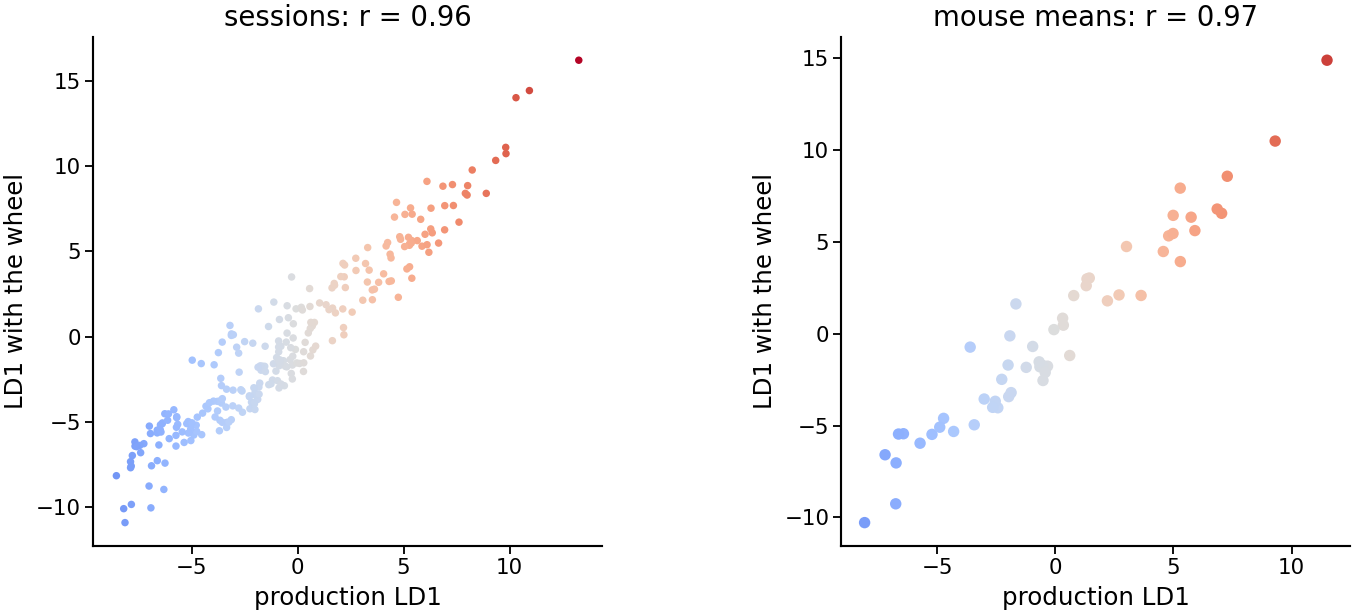

In [3]:
fig, axs = plt.subplots(1, 2, figsize=(7, 3))
for ax, Z_, Pp, lab in [(axs[0], LD.LD1_new, LD.LD1_prod, 'sessions'),
                        (axs[1], LD.groupby('mouse_name').LD1_new.mean(), LD.groupby('mouse_name').LD1_prod.mean(), 'mouse means')]:
    ax.scatter(Pp, Z_, s=6 if lab == 'sessions' else 14, c=ps.LD1_CMAP(ps.ld1_norm(LD.LD1_prod.to_numpy())(np.asarray(Pp))), lw=0)
    ax.set(xlabel='production LD1', ylabel='LD1 with the wheel', title=f'{lab}: r = {pearsonr(Pp, Z_)[0]:.2f}')
    ax.set_box_aspect(1)
plt.tight_layout()

## 1. Syllable correlations along LD1 — including the wheel states

Per trial bin (4 epochs × 10), the correlation across the 260 sessions between a state's occupancy in that bin and LD1. Grey band = 95 % of the same correlation with LD1 permuted across sessions (envelope over the states in a panel); traces solid where they leave it. Top row: the LD1 refitted with the wheel; bottom: the production LD1 (fit without the wheel), to see whether wheel use already lined up with it.

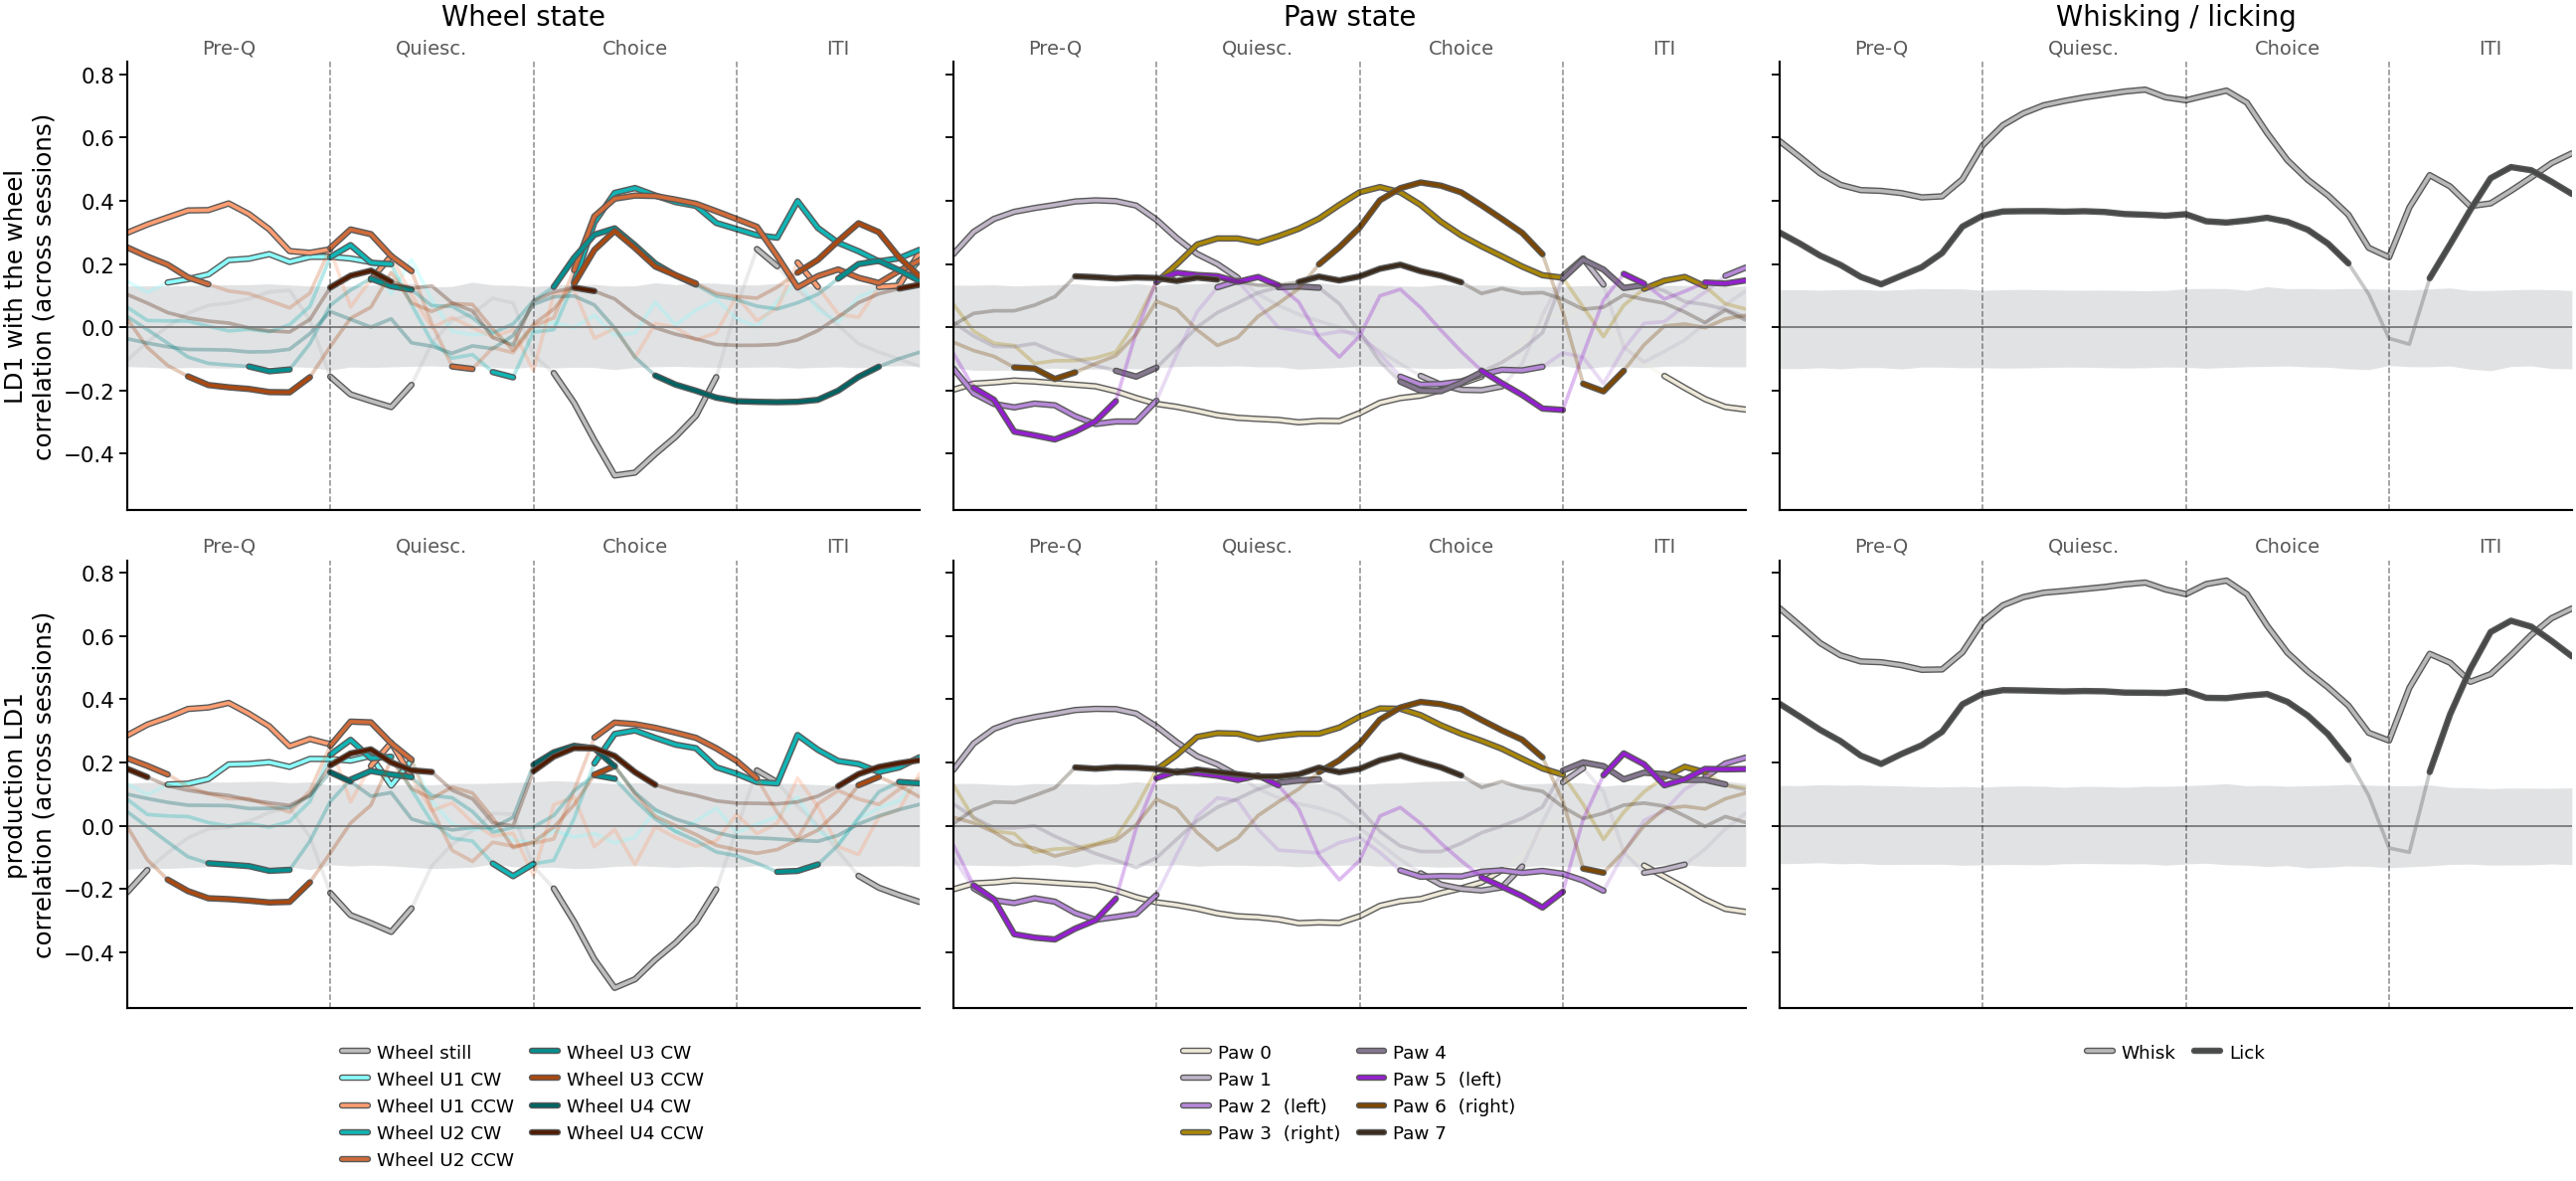

In [4]:
syl = pd.read_parquet(sorted(glob.glob(
    str(PI / 'data' / f'both_paws+wheelmov-sep_k8-{K_WHEEL}_own_lick-standard_proficient_8_k_10_bin_syllables_*')))[-1])
syl['session'] = syl['sample'].str[:36]
syl = syl[syl['session'].isin(sessions)]
tr = (syl.pivot(index=['mouse_name', 'session', 'sample'], columns='broader_label', values=['binned_sequence', 'wheel_binned_sequence'])
      .dropna().reset_index())
stack = lambda col: np.vstack([np.hstack(r) for r in tr[[(col, e) for e in EPOCHS]].to_numpy()]).astype(float)
codes, wheel = ps.paw_codes(stack('binned_sequence')), stack('wheel_binned_sequence')
paw, whisk, lick = ps.decode_syllables(codes)
OCC = np.stack([np.where(np.isnan(paw), np.nan, paw == k) for k in range(ps.N_PAW_STATES)] + [whisk, lick]
               + [np.where(np.isnan(wheel), np.nan, wheel == k) for k in range(K_WHEEL)], axis=-1)
sidx = tr[('session', '')].to_numpy()
with np.errstate(invalid='ignore'):
    SESS_OCC = np.stack([np.nanmean(OCC[sidx == s], axis=0) for s in sessions])     # (sessions, 40, 8 + 2 + K)
N_BINS = SESS_OCC.shape[1]
PAW_F, WL_F, WH_F = list(range(ps.N_PAW_STATES)), [8, 9], list(range(10, 10 + K_WHEEL))
LABEL = [ps.paw_label(k) for k in range(ps.N_PAW_STATES)] + ['Whisk', 'Lick'] + [f'Wheel {n}' for n in W_NAMES]
COLOR = list(ps.SYLLABLE_COLORS) + W_COLORS

def colwise_r(Mx, v):
    Mc = np.nan_to_num(Mx - np.nanmean(Mx, axis=0)); vc = v - v.mean()
    return (Mc.T @ vc) / (np.sqrt((Mc ** 2).sum(axis=0)) * np.sqrt((vc ** 2).sum()))
flat = SESS_OCC.reshape(len(sessions), -1)
STRUCT, BAND = {}, {}
rng = np.random.default_rng(SEED)
for key in ('LD1_new', 'LD1_prod'):
    v = LD[key].to_numpy()
    STRUCT[key] = colwise_r(flat, v).reshape(N_BINS, -1)
    null = np.stack([colwise_r(flat, rng.permutation(v)).reshape(N_BINS, -1) for _ in range(N_PERMS)])
    BAND[key] = np.nanpercentile(null, [2.5, 97.5], axis=0)
OUTLINE = [pe.Stroke(linewidth=plt.rcParams['lines.linewidth'] + 0.9, foreground='0.35'), pe.Normal()]

fig, axs = plt.subplots(2, 3, figsize=(12, 5.6), sharey=True)
for row, key in enumerate(('LD1_new', 'LD1_prod')):
    lo, hi = BAND[key]
    for ax, feats, title in zip(axs[row], [WH_F, PAW_F, WL_F], ['Wheel state', 'Paw state', 'Whisking / licking']):
        x = np.arange(N_BINS)
        ax.fill_between(x, lo[:, feats].min(1), hi[:, feats].max(1), color=ps.NULL_BAND, alpha=0.3, lw=0)
        for f in feats:
            y = STRUCT[key][:, f]
            ax.plot(x, y, color=COLOR[f], alpha=0.3)
            ax.plot(x, np.where((y >= lo[:, f]) & (y <= hi[:, f]), np.nan, y), color=COLOR[f], label=LABEL[f], path_effects=OUTLINE)
        ax.axhline(0, color=ps.NEUTRAL, lw=0.6); ps.epoch_lines(ax, N_BINS, label=True, names=ps.EPOCH_SHORT)
        ax.set(xlim=(0, N_BINS - 1), xticks=[])
        if row == 0: ax.set_title(title, pad=12)
        if row == 1: ax.legend(frameon=False, fontsize=6, ncol=2, loc='upper center', bbox_to_anchor=(0.5, -0.05))
    axs[row, 0].set_ylabel(('LD1 with the wheel' if key == 'LD1_new' else 'production LD1') + '\ncorrelation (across sessions)')
plt.tight_layout()

In [5]:
# summary: how strongly each state's occupancy tracks LD1 (max |r| over bins), new vs production LD1
summ = pd.DataFrame({'state': LABEL,
                     'max|r| with the wheel LD1': np.nanmax(np.abs(STRUCT['LD1_new']), axis=0),
                     'max|r| production LD1': np.nanmax(np.abs(STRUCT['LD1_prod']), axis=0),
                     'bins outside the band (wheel LD1)': ((STRUCT['LD1_new'] < BAND['LD1_new'][0]) | (STRUCT['LD1_new'] > BAND['LD1_new'][1])).sum(0),
                     'bins outside the band (production LD1)': ((STRUCT['LD1_prod'] < BAND['LD1_prod'][0]) | (STRUCT['LD1_prod'] > BAND['LD1_prod'][1])).sum(0)})
summ.round(3)

,state,max|r| with the wheel LD1,max|r| production LD1,bins outside the band (wheel LD1),bins outside the band (production LD1)
0,Paw 0,0.301,0.309,32,34
1,Paw 1,0.401,0.370,23,26
2,Paw 2 (left),0.306,0.298,24,24
3,Paw 3 (right),0.443,0.371,25,24
4,Paw 4,0.214,0.200,16,13
5,Paw 5 (left),0.355,0.360,26,29
6,Paw 6 (right),0.458,0.391,19,14
7,Paw 7,0.198,0.222,17,21
8,Whisk,0.752,0.776,40,40
9,Lick,0.507,0.648,37,37


In [6]:
# wheel states only, per epoch: mean r over the epoch's bins and the strongest bin outside the permutation band (new LD1)
rows = []
for f in WH_F:
    for e, ep in enumerate(EPOCHS):
        b = slice(e * 10, (e + 1) * 10)
        r = STRUCT['LD1_new'][b, f]; lo, hi = BAND['LD1_new'][0][b, f], BAND['LD1_new'][1][b, f]
        out = (r < lo) | (r > hi)
        rows.append(dict(state=LABEL[f], epoch=ep, mean_r=np.nanmean(r), n_sig_bins=int(out.sum()),
                         peak_sig_r=r[out][np.argmax(np.abs(r[out]))] if out.any() else np.nan))
W_EPOCH = pd.DataFrame(rows)
W_EPOCH.pivot(index='state', columns='epoch', values=['mean_r', 'n_sig_bins', 'peak_sig_r']).reindex(columns=EPOCHS, level=1).round(2)

mean_r                             n_sig_bins             \
epoch        Pre-quiescence Quiescence Choice   ITI Pre-quiescence Quiescence   
state                                                                           
Wheel U1 CCW           0.32       0.08  -0.01  0.11           10.0        3.0   
Wheel U1 CW            0.18       0.09   0.02  0.09            9.0        4.0   
Wheel U2 CCW           0.14       0.09   0.30  0.20            5.0        7.0   
Wheel U2 CW            0.02       0.04   0.28  0.28            0.0        6.0   
Wheel U3 CCW          -0.15       0.04   0.16  0.20            7.0        1.0   
Wheel U3 CW           -0.08       0.07   0.19  0.13            3.0        3.0   
Wheel U4 CCW           0.03       0.09   0.04  0.03            0.0        5.0   
Wheel U4 CW           -0.06      -0.02  -0.05 -0.18            0.0        0.0   
Wheel still            0.04      -0.09  -0.29  0.03            0.0        5.0   

                              peak_sig_r                          
epoch        Choice   ITI Pre-quiescence Quiescence Choice   ITI  
state                                                             
Wheel U1 CCW    1.0   5.0           0.39       0.25  -0.14  0.24  
Wheel U1 CW     0.0   3.0           0.23       0.22    NaN  0.21  
Wheel U2 CCW    8.0  10.0           0.25       0.31   0.42  0.34  
Wheel U2 CW     8.0  10.0            NaN       0.26   0.44  0.40  
Wheel U3 CCW    7.0   7.0          -0.21       0.17   0.30  0.33  
Wheel U3 CW     8.0   5.0          -0.14       0.15   0.31  0.21  
Wheel U4 CCW    2.0   2.0            NaN       0.18   0.13  0.13  
Wheel U4 CW     4.0   8.0            NaN        NaN  -0.22 -0.24  
Wheel still     9.0   3.0            NaN      -0.25  -0.47  0.25

## 2. Trial-metric correlations along LD1

`LDA_behavior`'s session summaries, computed exactly as in `fig_ld1` panel C (same trial file, same definitions, same exclusion of mice whose log training time is 0 or 1). Session-level Pearson r (training time: per mouse, mouse-mean LD1) and the stricter mouse-level test (mouse means); Benjamini–Hochberg FDR over the eight measures, separately per LD1 version.

In [7]:
tf = pd.read_parquet(TRIAL_META)
tt = pd.read_parquet(TRAINING_FILE); tt['log_training'] = np.log(tt['training_days'])
excluded = tt.loc[tt['log_training'].isin([0, 1]), 'mouse_name'].tolist()
tt = tt[~tt['mouse_name'].isin(excluded)]; tf = tf[~tf['mouse_name'].isin(excluded)].copy()
tf['choice'] = tf['choice'].map({'left': 0, 'right': 1, 'nan': np.nan})
tf['correct'] = (tf['feedback'] == 'correct').astype(int)
zc = tf[tf['contrast'] == 0].groupby(['session', 'block'])['choice'].mean().unstack('block')
bias_df = pd.DataFrame({'session': zc.index, 'bias': (zc[0.8] - zc[0.2]).values})
hc = tf[tf['contrast'] > 0].copy(); hc['expected_right'] = (hc['signed_contrast'] < 0).astype(int)
cb = hc.groupby('session').agg(choice_mean=('choice', 'mean'), expected_right_mean=('expected_right', 'mean')).reset_index()
cb['signed_choice_bias'] = cb['choice_mean'] - cb['expected_right_mean']; cb['choice_bias'] = cb['signed_choice_bias'].abs()
n_trials = tf.groupby('session')['choice'].count().rename('trial_count').reset_index()
acc = tf[tf['contrast'] > 0.5].groupby('session')['correct'].mean().rename('correct').reset_index()
ss = tf.groupby(['session', 'mouse_name']).agg(reaction=('reaction', 'median'), elongation=('elongation', 'median')).reset_index()
with np.errstate(invalid='ignore'):
    ss['log_reaction'], ss['log_elongation'] = np.log(ss['reaction']), np.log(ss['elongation'])
beh = (ss.merge(bias_df, on='session').merge(cb[['session', 'choice_bias', 'signed_choice_bias']], on='session').merge(acc, on='session')
         .merge(n_trials, on='session').merge(tt[['mouse_name', 'log_training']], on='mouse_name')
         .merge(LD, on=['session', 'mouse_name'])).replace([np.inf, -np.inf], np.nan)
C_VARS = [('correct', 'Accuracy'), ('choice_bias', 'Choice bias'), ('signed_choice_bias', 'Signed choice bias'),
          ('bias', 'Bias shift'), ('log_reaction', 'Reaction time'), ('log_elongation', 'Trial elongation'),
          ('trial_count', 'Trials completed'), ('log_training', 'Training time')]
rows = []
for key in ('LD1_new', 'LD1_prod'):
    bm = beh.groupby('mouse_name')[[key] + [v for v, _ in C_VARS if v != 'log_training']].mean()
    bm['log_training'] = beh.groupby('mouse_name')['log_training'].first()
    for v, name in C_VARS:
        d = (bm if v == 'log_training' else beh)[[key, v]].dropna()
        r, p = pearsonr(d[key], d[v])
        dm = bm[[key, v]].dropna(); rm, pm_ = pearsonr(dm[key], dm[v])
        rows.append(dict(LD1=key, measure=name, r=r, p=p, n=len(d), r_mice=rm, p_mice=pm_))
TS = pd.DataFrame(rows)
for key in ('LD1_new', 'LD1_prod'):
    m = TS.LD1 == key
    TS.loc[m, 'q'] = multipletests(TS.loc[m, 'p'], method='fdr_bh')[1]
    TS.loc[m, 'q_mice'] = multipletests(TS.loc[m, 'p_mice'], method='fdr_bh')[1]
TS.pivot(index='measure', columns='LD1', values=['r', 'q', 'r_mice', 'q_mice']).reindex([n for _, n in C_VARS]).round(3)

r                q           r_mice           q_mice  \
LD1                LD1_new LD1_prod LD1_new LD1_prod LD1_new LD1_prod LD1_new   
measure                                                                         
Accuracy             0.191    0.184   0.006    0.012   0.254    0.214   0.171   
Choice bias         -0.196   -0.224   0.006    0.002  -0.184   -0.192   0.294   
Signed choice bias   0.034    0.039   0.810    0.551   0.063    0.053   0.649   
Bias shift           0.011   -0.044   0.907    0.551   0.077    0.045   0.649   
Reaction time       -0.301   -0.346   0.000    0.000  -0.382   -0.435   0.018   
Trial elongation     0.008    0.057   0.907    0.507   0.105    0.159   0.602   
Trials completed    -0.132   -0.063   0.067    0.507  -0.215   -0.152   0.238   
Training time       -0.406   -0.344   0.006    0.022  -0.406   -0.344   0.018   

                             
LD1                LD1_prod  
measure                      
Accuracy              0.322  
Choice bias           0.329  
Signed choice bias    0.748  
Bias shift            0.748  
Reaction time         0.008  
Trial elongation      0.363  
Trials completed      0.363  
Training time         0.044

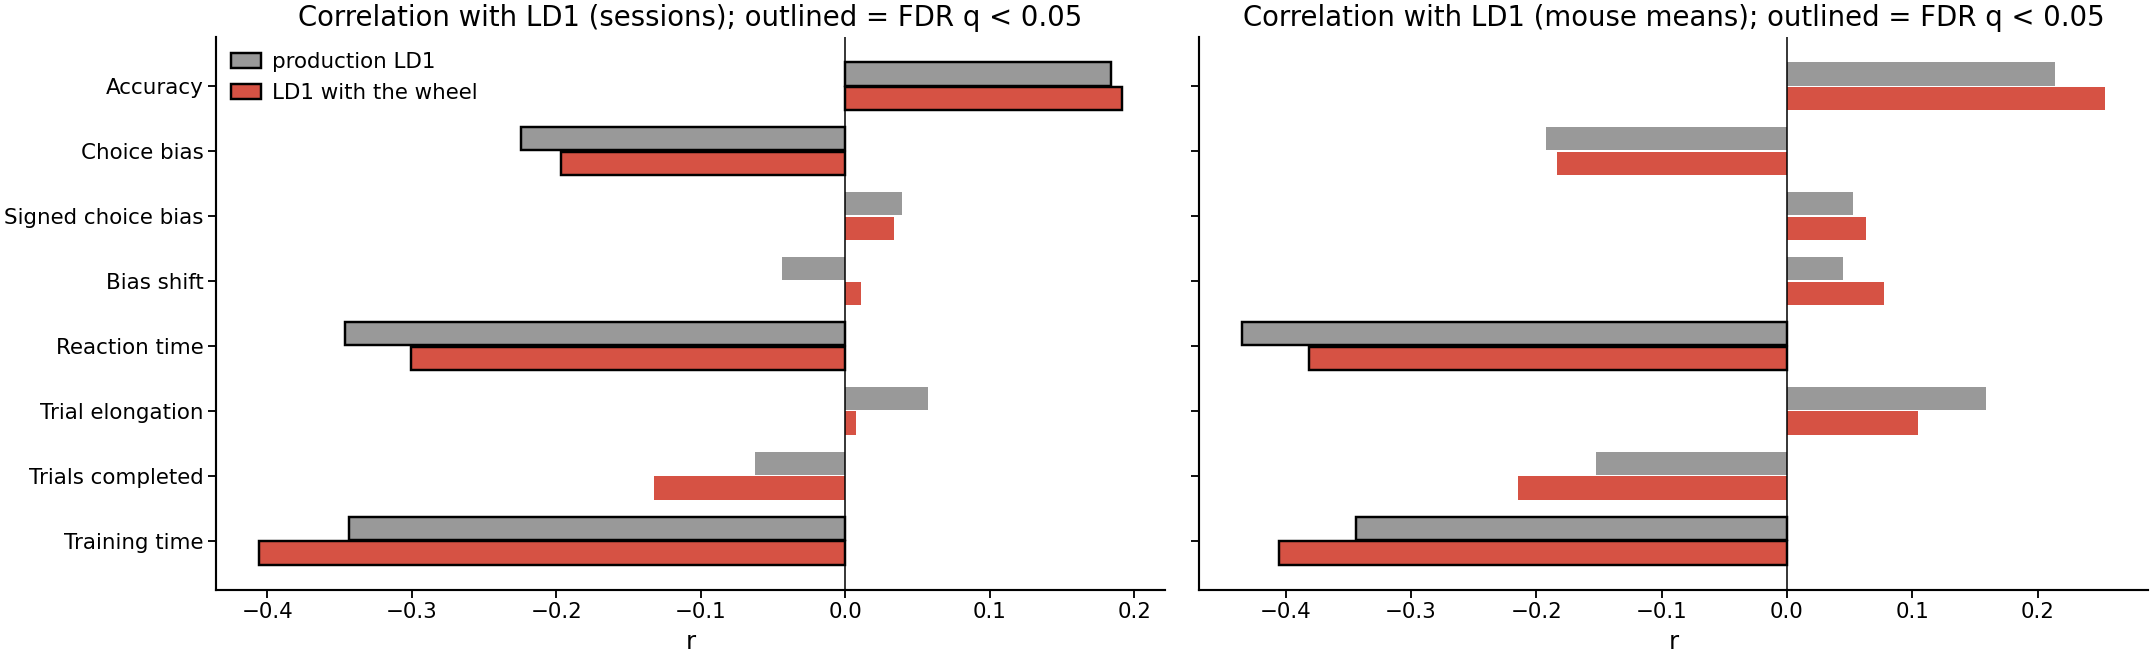

In [8]:
fig, axs = plt.subplots(1, 2, figsize=(10, 3.2), sharey=True)
y = np.arange(len(C_VARS))
for ax, (rc, qc, title) in zip(axs, [('r', 'q', 'sessions'), ('r_mice', 'q_mice', 'mouse means')]):
    for j, (key, col, lab) in enumerate([('LD1_prod', '0.6', 'production LD1'), ('LD1_new', ps.LD1_CMAP(0.9), 'LD1 with the wheel')]):
        d = TS[TS.LD1 == key].set_index('measure').reindex([n for _, n in C_VARS])
        ax.barh(y + (j - 0.5) * 0.38, d[rc], height=0.36, color=col, label=lab,
                edgecolor=['k' if q < 0.05 else 'none' for q in d[qc]], lw=0.8)
    ax.axvline(0, color='k', lw=0.5); ax.set(title=f'Correlation with LD1 ({title}); outlined = FDR q < 0.05', xlabel='r')
axs[0].set_yticks(y, [n for _, n in C_VARS]); axs[0].invert_yaxis(); axs[0].legend(frameon=False, fontsize=7)
plt.tight_layout()

## 3. Engagement (GLM-HMM) measures along LD1

As `fig_engagement`: the K = 2 posteriors of `GLM-HMM/merged_behavioral_and_states.pqt`, each session cut to its first `N_TRUNC` (400) trials; engaged = P(engaged) ≥ 0.5. Pearson r with LD1 at the session level and with mouse means; 'switches | accuracy' is the partial correlation with easy-trial accuracy regressed out of both. FDR (BH) over the family, separately per LD1 version.

In [9]:
import statsmodels.formula.api as smf
GLM = PI / 'GLM-HMM'
N_TRUNC, I_K, H_STEPS = 400, 4, [(2, 3), (2, 4)]
gt = pd.read_parquet(GLM / 'merged_behavioral_and_states.pqt')
gt = gt[gt['eid'].isin(sessions)].copy()
gt['trial_id'] = gt.groupby('eid').cumcount()
gt['engaged'] = gt['p_state1'] >= 0.5
gt['correct'] = (gt['rewarded'] == 1).astype(int)
gt = gt[gt['trial_id'] < N_TRUNC]
def per_session(g):
    e = g['engaged'].to_numpy(); a, b = e[:-1], e[1:]
    return pd.Series({'frac_engaged': e.mean(), 'log_ratio': np.log(g['p_state1'].mean() / g['p_state2'].mean()),
                      'switches': (a != b).sum(),
                      'p_stay_eng': (a & b).sum() / a.sum() if a.sum() else np.nan,
                      'p_stay_dis': (~a & ~b).sum() / (~a).sum() if (~a).sum() else np.nan})
ENG = gt.groupby('eid')[['engaged', 'p_state1', 'p_state2']].apply(per_session)
ENG = ENG.join(gt[gt['signed_contrast'].abs() >= 0.25].groupby('eid')['correct'].mean().rename('p_easy'))
loso = pd.read_csv(GLM / 'k2_k3_pilot' / 'loso_k2_k3_k4_k5_wide.csv').set_index('held_out_session')
for a, b in H_STEPS:
    ENG = ENG.join((loso[f'bpt_K{b}'] - loso[f'bpt_K{a}']).rename(f'gain_{a}{b}'), how='left')
post = pd.read_parquet(GLM / 'k2_k3_pilot' / 'all_k_posteriors.parquet', filters=[('K', '==', I_K)],
                       columns=['eid', 'trial_idx', 'state', 'posterior'])
dom = post.sort_values('posterior').drop_duplicates(['eid', 'trial_idx'], keep='last').sort_values(['eid', 'trial_idx'])
dom = dom[dom['trial_idx'] < N_TRUNC]
ENG = ENG.join(dom.groupby('eid')['state'].agg(lambda x: int((np.diff(x.to_numpy()) != 0).sum())).rename(f'switches_k{I_K}'))
ENG = ENG.join(LD.set_index('session')[['mouse_name', 'LD1_new', 'LD1_prod']], how='inner')
print(f'{len(ENG)} sessions with GLM-HMM posteriors, {ENG.mouse_name.nunique()} mice')
E_TESTS = [('frac_engaged', 'Engaged trials', None), ('log_ratio', 'Engaged log ratio', None),
           ('switches', 'State switches', None), ('switches', 'Switches | accuracy', 'p_easy'),
           ('gain_23', 'Held-out gain K = 2 → 3', None), ('gain_24', 'Held-out gain K = 2 → 4', None),
           (f'switches_k{I_K}', f'Switches, K = {I_K}', None),
           ('p_stay_eng', 'Stay engaged', None), ('p_stay_dis', 'Stay disengaged', None)]
def eng_stats(frame, key):
    rows = []
    for col, name, cov in E_TESTS:
        d = frame[[key, col] + ([cov] if cov else [])].dropna().rename(columns={key: 'LD1'})
        if cov:
            rx = smf.ols(f'LD1 ~ {cov}', data=d).fit().resid; ry = smf.ols(f'{col} ~ {cov}', data=d).fit().resid
            r = pearsonr(rx, ry)[0]; p = smf.ols(f'{col} ~ LD1 + {cov}', data=d).fit().pvalues['LD1']
        else:
            r, p = pearsonr(d['LD1'], d[col])
        rows.append(dict(measure=name, r=r, p=p, n=len(d)))
    t = pd.DataFrame(rows); t['q'] = multipletests(t['p'], method='fdr_bh')[1]
    return t.set_index('measure')
ENG_M = ENG.groupby('mouse_name').mean(numeric_only=True)
ES = pd.concat({(lvl, key): eng_stats(fr, key) for lvl, fr in [('sessions', ENG), ('mice', ENG_M)]
                for key in ('LD1_new', 'LD1_prod')}, axis=1)
ES.round(3)

244 sessions with GLM-HMM posteriors, 56 mice


sessions                                          \
                         LD1_new                    LD1_prod               
                               r      p    n      q        r      p    n   
measure                                                                    
Engaged trials             0.009  0.886  244  0.886    0.037  0.564  244   
Engaged log ratio          0.221  0.000  244  0.001    0.239  0.000  244   
State switches            -0.352  0.000  244  0.000   -0.342  0.000  244   
Switches | accuracy       -0.255  0.000  244  0.000   -0.242  0.000  244   
Held-out gain K = 2 → 3   -0.089  0.178  231  0.201   -0.090  0.173  231   
Held-out gain K = 2 → 4   -0.149  0.024  231  0.030   -0.150  0.022  231   
Switches, K = 4           -0.272  0.000  231  0.000   -0.261  0.000  231   
Stay engaged               0.314  0.000  244  0.000    0.317  0.000  244   
Stay disengaged            0.191  0.004  228  0.006    0.168  0.011  228   

                                  mice                                        \
                               LD1_new                   LD1_prod              
                             q       r      p   n      q        r      p   n   
measure                                                                        
Engaged trials           0.564   0.003  0.981  56  0.981    0.004  0.976  56   
Engaged log ratio        0.000   0.266  0.048  56  0.086    0.248  0.065  56   
State switches           0.000  -0.441  0.001  56  0.005   -0.414  0.002  56   
Switches | accuracy      0.000  -0.354  0.008  56  0.024   -0.330  0.014  56   
Held-out gain K = 2 → 3  0.195  -0.155  0.272  52  0.306   -0.152  0.283  52   
Held-out gain K = 2 → 4  0.029  -0.225  0.110  52  0.141   -0.229  0.102  52   
Switches, K = 4          0.000  -0.296  0.033  52  0.075   -0.274  0.049  52   
Stay engaged             0.000   0.422  0.001  56  0.005    0.397  0.002  56   
Stay disengaged          0.017   0.217  0.108  56  0.141    0.223  0.098  56   

                                
                                
                             q  
measure                         
Engaged trials           0.976  
Engaged log ratio        0.118  
State switches           0.011  
Switches | accuracy      0.042  
Held-out gain K = 2 → 3  0.318  
Held-out gain K = 2 → 4  0.131  
Switches, K = 4          0.111  
Stay engaged             0.011  
Stay disengaged          0.131

/tmp/ipykernel_41114/4019069966.py:5: PerformanceWarning: indexing past lexsort depth may impact performance.
  d = ES[(lvl, key)].reindex(names)


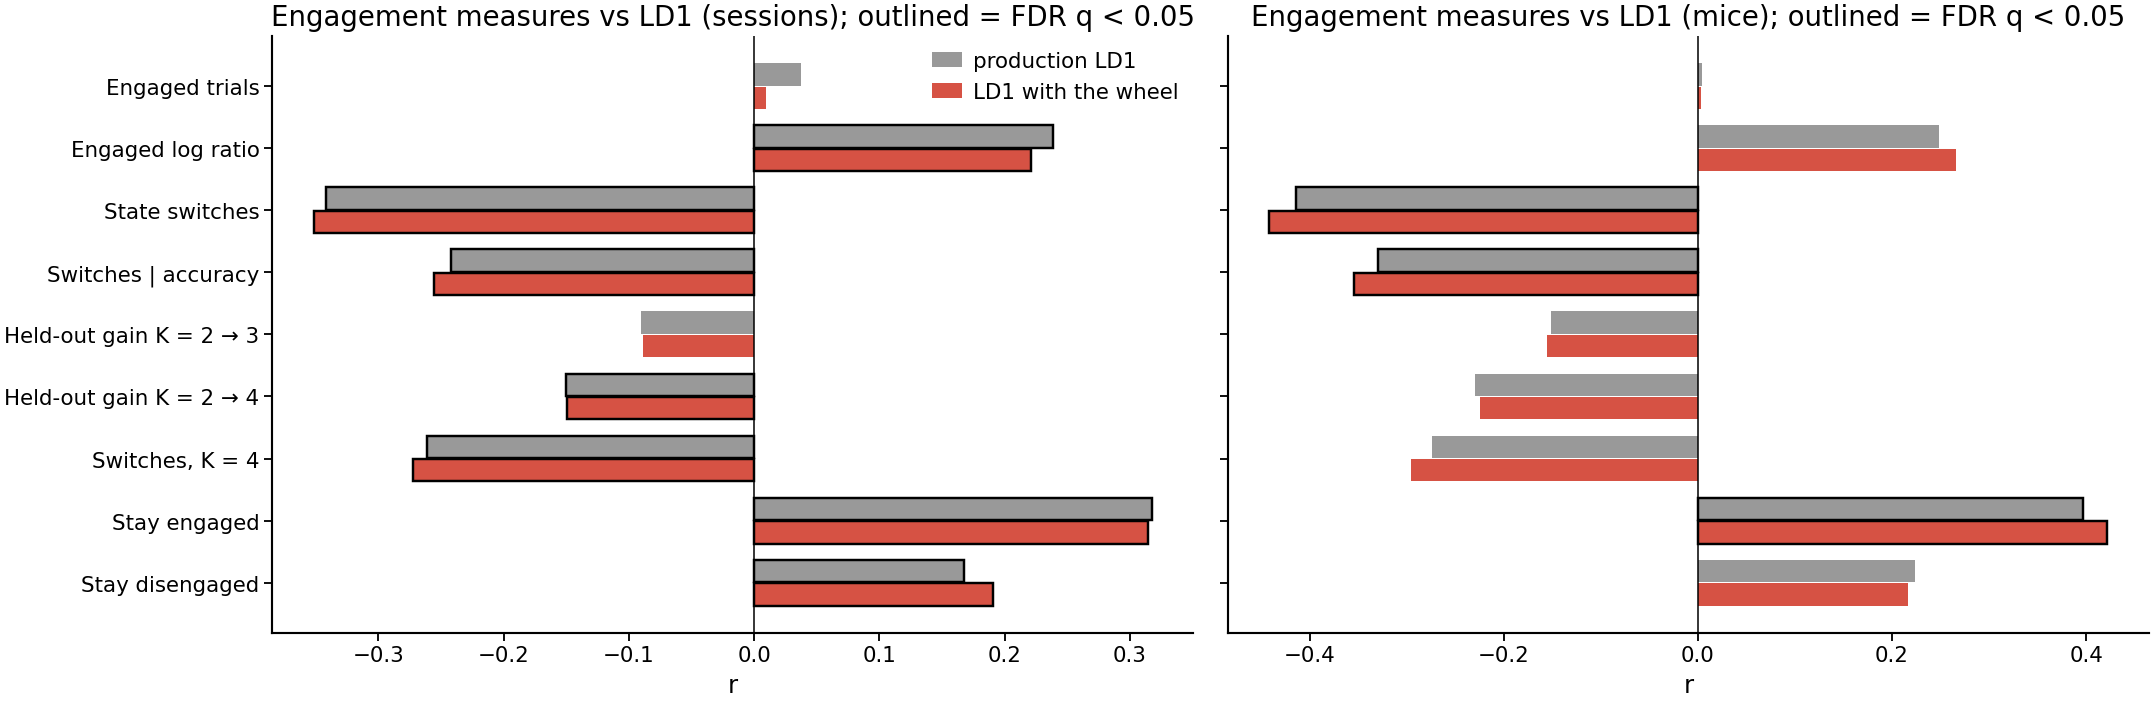

In [10]:
fig, axs = plt.subplots(1, 2, figsize=(10, 3.4), sharey=True)
names = [n for _, n, _ in E_TESTS]; y = np.arange(len(names))
for ax, lvl in zip(axs, ['sessions', 'mice']):
    for j, (key, col, lab) in enumerate([('LD1_prod', '0.6', 'production LD1'), ('LD1_new', ps.LD1_CMAP(0.9), 'LD1 with the wheel')]):
        d = ES[(lvl, key)].reindex(names)
        ax.barh(y + (j - 0.5) * 0.38, d['r'], height=0.36, color=col, label=lab,
                edgecolor=['k' if q < 0.05 else 'none' for q in d['q']], lw=0.8)
    ax.axvline(0, color='k', lw=0.5); ax.set(title=f'Engagement measures vs LD1 ({lvl}); outlined = FDR q < 0.05', xlabel='r')
axs[0].set_yticks(y, names); axs[0].invert_yaxis(); axs[0].legend(frameon=False, fontsize=7)
plt.tight_layout()

## 4. Neural correlates along LD1

`fig_neural`'s tests unchanged: its QC settings, the cached metric tables, `apply_cohort(..., 'common')`, `run_tests` (GLM slope of LD1 with region and trial-count covariates; session-level permutation, 2000; FDR within each metric), response-onset tests left out as in the figure. Run twice, with the production LD1 and with the LD1 refitted with the wheel, both mapped onto the tables by session; neural sessions outside the 260 LDA sessions have no LD1 and drop out of both.

In [11]:
sys.path.insert(0, str(PI / 'neural'))
import lda1_neural_metrics as nm
import behaviour_models as bm
bm._numpy2_pickles()
cfg = nm.default_config()
cfg.update(MIN_FR_HZ=1.0, FR_FLOOR_REQUIRE='both', FR_FLOOR_SOURCE='session', UNIFORM_FR_FLOOR=True,
           MIN_PRESENCE_RATIO=0.90, MIN_NEURONS=15, MIN_NEURONS_RSC=None, LD1_SOURCE='current')
tables = nm.apply_cohort(nm.load_tables(cfg=cfg, verbose=False), cfg, 'common', verbose=False)
maps = {k: dict(zip(LD['session'], LD[k])) for k in ('LD1_new', 'LD1_prod')}
for k, t in tables.items():
    if isinstance(t, pd.DataFrame) and 'session' in t.columns:
        for c, m in maps.items():
            t[c] = t['session'].map(m)
def neural_tests(pred):
    res = nm.run_tests(tables, cfg, predictor=pred, verbose=False)
    res = res[res['test'] != 'Response onset'].copy()
    res['q_fdr_metric'] = res.groupby('metric')['p_perm'].transform(lambda p: multipletests(p, method='fdr_bh')[1])
    return res
NR = {k: neural_tests(k) for k in ('LD1_prod', 'LD1_new')}
cols = [c for c in ['metric', 'test', 'n_sessions', 'slope', 'r_partial', 'p_perm', 'q_fdr_metric'] if c in NR['LD1_prod'].columns]
NEU = NR['LD1_prod'][cols].merge(NR['LD1_new'][cols], on=['metric', 'test'], suffixes=(' (production)', ' (with wheel)'))
NEU.round(4)

,metric,test,n_sessions (production),slope (production),r_partial (production),p_perm (production),q_fdr_metric (production),n_sessions (with wheel),slope (with wheel),r_partial (with wheel),p_perm (with wheel),q_fdr_metric (with wheel)
0,Firing rate,Baseline,204,0.0136,0.0393,0.0450,0.1350,204,0.0130,0.0413,0.0365,0.1095
1,Firing rate,Post-stimulus,204,0.0037,0.0112,0.5185,0.5185,204,0.0034,0.0114,0.5015,0.5015
2,Firing rate,Response magnitude,204,0.0374,0.0132,0.2555,0.3833,204,0.0443,0.0172,0.1425,0.2138
3,Fano factor,Baseline,204,-0.0037,-0.0251,0.2135,0.2135,204,-0.0027,-0.0202,0.3305,0.3305
4,Fano factor,Post-stimulus,204,-0.0147,-0.0921,0.0000,0.0000,204,-0.0127,-0.0867,0.0005,0.0008
5,Fano factor,Response magnitude,204,-0.0237,-0.0928,0.0000,0.0000,204,-0.0219,-0.0940,0.0000,0.0000
6,Noise correlation,Baseline,203,-0.0007,-0.1585,0.0140,0.0140,203,-0.0007,-0.1579,0.0130,0.0130
7,Noise correlation,Post-stimulus,203,-0.0011,-0.2233,0.0005,0.0015,203,-0.0010,-0.2263,0.0000,0.0000
8,Noise correlation,Response magnitude,203,-0.0003,-0.1412,0.0130,0.0140,203,-0.0003,-0.1488,0.0100,0.0130


## Combined figure: every test, with and without the wheel

In the style of `figure_generation/fig_lab_controls` (compact version). **a** LD1 refitted with this wheel set against the production (no-wheel) LD1. **b** the wheel states' correlation with LD1, mean per epoch, for both LD1s (dot: at least half the epoch's bins outside the permutation band). **c** behaviour and GLM-HMM engagement measures against LD1, across sessions and across mouse means. **d** neural correlates (fig_neural's partial r). Grey = no wheel, colour = with the wheel; filled = BH q < 0.05 in its own family (the tables above), open = n.s. Writes `figure_generation/figures/fig_lda_wheel_correlates_<VARIANT>.pdf` (+ dated svg).

In [ ]:
# ---------------------------------------------------------------- combined figure: every test, wheel vs no wheel
# In the style of figure_generation/fig_lab_controls (compact version): one row per correlate, a dot with its 95 % CI,
# filled where that test's BH q < 0.05 (its own family, as in the tables above), open otherwise. Two dots per row:
# production LD1 (no wheel, grey) above, the LD1 refitted with this wheel set (colour) below.
from datetime import date
from matplotlib.lines import Line2D
from matplotlib.transforms import blended_transform_factory
FIGDIR = PI / 'figure_generation'
if str(FIGDIR) not in sys.path:
    sys.path.insert(0, str(FIGDIR))
import fig_layout as fl

PROD_C, NEW_C = '0.55', ps.LD1_CMAP(0.9)
VERS = [('LD1_prod', PROD_C, 'No wheel (production LD1)'), ('LD1_new', NEW_C, f'With the wheel ({VARIANT}: {K_WHEEL} states)')]
OFF = 0.18
N_MICE = LD['mouse_name'].nunique()

def fisher_ci(r, n):
    z, se = np.arctanh(np.clip(r, -0.999, 0.999)), 1 / np.sqrt(max(n - 3, 1))
    return np.tanh(z - 1.96 * se), np.tanh(z + 1.96 * se)

# rows: (group, label, {key: (r, n, q)}) for each column
def beh_rows(level):
    out = []
    for _, name in C_VARS:
        vals = {}
        for key, _, _ in VERS:
            t = TS[(TS.LD1 == key) & (TS.measure == name)].iloc[0]
            vals[key] = ((t['r'], t['n'], t['q']) if level == 'sessions' and name != 'Training time'
                         else (t['r_mice'], N_MICE, t['q_mice']) if level == 'mice' else (np.nan, 0, 1))
        out.append(('Task', name + ('*' if name == 'Training time' else ''), vals))
    for _, name, _ in E_TESTS:
        vals = {key: (ES[(level, key)].loc[name, 'r'], ES[(level, key)].loc[name, 'n'], ES[(level, key)].loc[name, 'q'])
                for key, _, _ in VERS}
        out.append(('Internal states (GLM-HMM)', name, vals))
    return out

def neural_rows():
    out = []
    for _, r in NR['LD1_prod'][['metric', 'test']].iterrows():
        vals = {}
        for key, _, _ in VERS:
            t = NR[key][(NR[key].metric == r.metric) & (NR[key].test == r.test)].iloc[0]
            vals[key] = (t['r_partial'], t['n_sessions'], t['q_fdr_metric'])
        short = {'Firing rate': 'FR', 'Fano factor': 'FF', 'Noise correlation': 'r$_{SC}$'}[r.metric]
        lab = {'Baseline': 'pre', 'Post-stimulus': 'post', 'Response magnitude': 'change'}[r.test]
        out.append((r.metric, f'{short}, {lab}', vals))
    return out

def forest(ax, rows, labels=True, ci=True):
    y, ticks, names, heads, last = 0, [], [], [], None
    for group, name, vals in rows:
        if group != last:
            heads.append((y, group)); y += 1; last = group
        for j, (key, col, _) in enumerate(VERS):
            r, n, q = vals[key]
            if not np.isfinite(r):
                continue
            dy = -OFF if j == 0 else OFF
            if ci:
                lo, hi = fisher_ci(r, n)
                ax.plot([lo, hi], [y + dy] * 2, color=col, lw=0.8, solid_capstyle='butt')
            ax.plot(r, y + dy, 'o', ms=3.2, color=col, mfc=col if q < 0.05 else 'white', mew=0.8, zorder=3)
        ticks.append(y); names.append(name); y += 1
    ax.axvline(0, color='0.5', lw=0.5, zorder=0)
    ax.set_yticks(ticks); ax.set_yticklabels(names if labels else [])
    ax.tick_params(axis='y', length=0); ax.set_ylim(y - 0.4, -0.7); ax.spines['left'].set_visible(False)
    if labels:
        tr = blended_transform_factory(ax.transAxes, ax.transData)
        for hy, g in heads:
            ax.text(-0.03, hy, g, transform=tr, ha='right', va='center', fontweight='bold',
                    fontsize=plt.rcParams['font.size'] * 0.9)
    return ax

def draw_scatter(fig, spec):
    ax = fig.add_subplot(spec)
    pm, nm_ = LD.groupby('mouse_name').LD1_prod.mean(), LD.groupby('mouse_name').LD1_new.mean()
    ax.scatter(LD.LD1_prod, LD.LD1_new, s=3, color='0.8', lw=0, label='sessions')
    ax.scatter(pm, nm_, s=9, c=ps.LD1_CMAP(ps.ld1_norm(LD.LD1_prod.to_numpy())(pm.to_numpy())), lw=0.3, ec='0.3',
               label='mouse means')
    ax.set(xlabel='LD1, no wheel', ylabel='LD1 with the wheel')
    ax.set_title(f'r = {pearsonr(LD.LD1_prod, LD.LD1_new)[0]:.2f} (sessions), {pearsonr(pm, nm_)[0]:.2f} (mice)\n'
                 f'between-mouse share {E_base.axis_share[0]:.3f} → {E_new.axis_share[0]:.3f}',
                 fontsize=plt.rcParams['font.size'] * 0.85)
    ax.set_box_aspect(1)
    return [ax]

def draw_wheel_heat(fig, spec):
    g = spec.subgridspec(1, 2, wspace=0.08)
    axes = []
    for j, (key, title) in enumerate([('LD1_prod', 'No-wheel LD1'), ('LD1_new', 'LD1 with the wheel')]):
        ax = fig.add_subplot(g[j]); axes.append(ax)
        M = np.array([[np.nanmean(STRUCT[key][e * 10:(e + 1) * 10, f]) for e in range(len(EPOCHS))] for f in WH_F])
        out = np.array([[((STRUCT[key][e * 10:(e + 1) * 10, f] < BAND[key][0][e * 10:(e + 1) * 10, f]) |
                          (STRUCT[key][e * 10:(e + 1) * 10, f] > BAND[key][1][e * 10:(e + 1) * 10, f])).sum()
                         for e in range(len(EPOCHS))] for f in WH_F])
        im = ax.imshow(M, cmap='RdBu_r', vmin=-0.45, vmax=0.45, aspect='auto')
        for (i_, e_), v in np.ndenumerate(out):
            if v >= 5:                       # at least half the epoch's bins outside the permutation band
                ax.text(e_, i_, '•', ha='center', va='center', fontsize=6, color='k')
        ax.set_xticks(range(len(EPOCHS)), ps.EPOCH_SHORT, rotation=45, ha='right')
        ax.set_yticks(range(len(WH_F)), [LABEL[f].replace('Wheel ', '') for f in WH_F] if j == 0 else [])
        ax.set_title(title, fontsize=plt.rcParams['font.size'] * 0.9)
        for s_ in ax.spines.values():
            s_.set_visible(False)
        ax.tick_params(length=0)
    cb = fig.colorbar(im, ax=axes, shrink=0.8, pad=0.03)
    cb.set_label('mean r with LD1\n(per epoch)', fontsize=plt.rcParams['font.size'] * 0.8)
    return axes

fig = plt.figure(figsize=(fl.FIG_WIDTH, 7.6))
outer = fig.add_gridspec(2, 1, height_ratios=[1, 2.2], hspace=0.32, left=0.2, right=0.97, top=0.95, bottom=0.07)
top = outer[0].subgridspec(1, 2, width_ratios=[1, 1.6], wspace=0.45)
bot = outer[1].subgridspec(1, 3, width_ratios=[1, 1, 1.05], wspace=0.15)
panels = {'a': draw_scatter(fig, top[0]), 'b': draw_wheel_heat(fig, top[1])}
for k, (level, title) in enumerate([('sessions', 'Across sessions'), ('mice', 'Across mice')]):
    ax = fig.add_subplot(bot[k]); forest(ax, beh_rows(level), labels=k == 0)
    ax.set_xlim(-0.75, 0.75); ax.set_title(title, fontsize=plt.rcParams['font.size'] * 0.9)
    ax.set_xlabel('Pearson r with LD1'); panels['c' if k == 0 else 'c2'] = [ax]
g_n = bot[2].subgridspec(2, 1, height_ratios=[1, 1.15], hspace=0.3)
ax = fig.add_subplot(g_n[0]); forest(ax, neural_rows(), labels=True, ci=False)
ax.set_xlim(-0.4, 0.4); ax.set_xlabel('Partial r with LD1\n(region, trial-count covariates)')
ax.set_title('Neural (across recordings)', fontsize=plt.rcParams['font.size'] * 0.9)
ax.yaxis.tick_right(); ax.tick_params(axis='y', labelright=True, labelleft=False, length=0)
for t in list(ax.texts):                            # group heads to the right side as well
    t.set_x(1.03); t.set_ha('left')
panels['d'] = [ax]
leg = fig.add_subplot(g_n[1]); leg.set_axis_off()
leg.legend(handles=[Line2D([], [], marker='o', ls='-', lw=0.8, ms=3.2, color=c, label=l) for _, c, l in VERS]
           + [Line2D([], [], marker='o', ls='', ms=3.2, color='0.3', label='filled: BH q < 0.05'),
              Line2D([], [], marker='o', ls='', ms=3.2, color='0.3', mfc='white', label='open: n.s.')],
           frameon=False, loc='center', handlelength=1.6, fontsize=plt.rcParams['legend.fontsize'] * 0.95)
leg.text(0.5, 0.0, '* one value per mouse (no session column)\n95 % CI: Fisher z; neural: no CI (q from the session permutation test)\n'
         '• in b: ≥ half the epoch\'s bins outside the permutation band', ha='center', va='top',
         transform=leg.transAxes, fontsize=plt.rcParams['font.size'] * 0.7, color='0.35')
fl.place_letters(fig, {k: v for k, v in panels.items() if k != 'c2'}, rows=['ab', 'cd'], left='ac')
plt.show()
OUT = FIGDIR / 'figures'
for path in [OUT / f"fig_lda_wheel_correlates_{VARIANT}_{date.today().strftime('%d-%m-%Y')}.svg",
             OUT / f'fig_lda_wheel_correlates_{VARIANT}.pdf']:
    fig.savefig(path)
    print('wrote', path.relative_to(PI))
